## Part 1: Starting Simple - Create Initial Prompts

**Objective:** Create basic zero-shot prompts for three different task types and establish a baseline.

### Step 1: Setup Your Environment

In [19]:
%pip install openai

Note: you may need to restart the kernel to use updated packages.


In [20]:
%pip install openai python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [21]:
%pip install python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [22]:
import os
from openai import OpenAI
import json
from collections import Counter
import time
from dotenv import load_dotenv

load_dotenv()

api_key = os.getenv("OPENAI_API_KEY")

if not api_key:
    raise ValueError("OPENAI_API_KEY not found")

client = OpenAI(api_key=api_key)

MODEL = "gpt-4o-mini"

print("✅ Setup complete! OpenAI client initialized.")

✅ Setup complete! OpenAI client initialized.


In [23]:
response = client.responses.create(
    model=MODEL,
    input="Reply with exactly: Setup successful"
)

print(response.output_text)

Setup successful


In [24]:
def call_openai(prompt, system_message="You are a helpful assistant.",
                temperature=0.7, max_tokens=None, seed=None):
    """Helper function to call OpenAI API with specified parameters."""
    try:
        params = {
            "model": MODEL,
            "messages": [
                {"role": "system", "content": system_message},
                {"role": "user", "content": prompt}
            ],
            "temperature": temperature
        }

        if max_tokens is not None:
            params["max_tokens"] = max_tokens

        if seed is not None:
            params["seed"] = seed

        response = client.chat.completions.create(**params)

        return response.choices[0].message.content

    except Exception as e:
        print(f"API call failed: {e}")
        raise


def display_response(title, response, params=None):
    """Display a response with formatting."""
    print(f"\n{'=' * 60}")
    print(f"📝 {title}")

    if params:
        print(f"Parameters: {params}")

    print(f"{'=' * 60}")
    print(response)
    print(f"{'=' * 60}\n")


def count_tokens_approx(text):
    """Approximate token count (roughly 4 characters per token)."""
    return len(text) // 4


print("✅ Helper functions loaded!")

✅ Helper functions loaded!


In [25]:
result = call_openai(
    "Reply with exactly: Setup successful",
    temperature=0
)

display_response("API Connection Test", result)


📝 API Connection Test
Setup successful



### Step 2: Create Initial Prompts

**What to do:**
1. Write three basic zero-shot prompts (one for each task type: Sentiment Analysis, Product Description, Data Extraction)
2. Test each prompt once to see initial results

In [26]:
sentiment_prompt_v1 = """
Classify this customer message:
"I love this product! It's exactly what I needed."
"""

result = call_openai(sentiment_prompt_v1)

display_response("Sentiment Analysis V1", result)


📝 Sentiment Analysis V1
The customer message can be classified as **Positive Feedback** or **Customer Satisfaction**.



In [27]:
product_prompt_v1 = """
Create a product description for a wireless mouse
that costs $29.99.
"""

result = call_openai(product_prompt_v1)

display_response("Product Description V1", result)


📝 Product Description V1
**Product Name: SwiftClick Wireless Mouse**

**Price: $29.99**

**Description:**

Experience seamless navigation and effortless control with the SwiftClick Wireless Mouse, the perfect companion for your laptop or desktop. Designed for both productivity and comfort, this sleek and modern mouse offers a blend of style and functionality that enhances your computing experience.

**Key Features:**

- **Wireless Freedom:** Say goodbye to tangled cords! The SwiftClick connects via a reliable 2.4GHz wireless connection, providing a strong signal with a range of up to 33 feet. Enjoy the freedom to move and work from anywhere in the room.

- **Ergonomic Design:** Crafted with an ergonomic shape that fits comfortably in your hand, the SwiftClick reduces wrist strain during long hours of use. Its lightweight design makes it easy to carry, whether you’re at home, in the office, or on the go.

- **Precision Tracking:** Equipped with advanced optical tracking technology, thi

In [28]:
extraction_prompt_v1 = """
Extract information from this customer feedback:
"I ordered item #12345 on March 15th.
The delivery was fast but the packaging was damaged."
"""

result = call_openai(extraction_prompt_v1)

display_response("Data Extraction V1", result)


📝 Data Extraction V1
Here is the extracted information from the customer feedback:

- **Item Number**: 12345
- **Order Date**: March 15th
- **Delivery Speed**: Fast
- **Packaging Condition**: Damaged



### Step 3: Run Prompts 5 Times

**What to do:**
1. Run each prompt 5 times using a helper function
2. Record all responses
3. Analyze consistency between prompts

In [29]:
def test_prompt(prompt, runs=5):
    results = []

    for i in range(runs):
        response = call_openai(prompt)
        results.append(response)
        print(f"Run {i + 1}: {response}\n")

    return results

In [30]:
sentiment_results_5 = test_prompt(sentiment_prompt_v1, runs=5)

Run 1: The customer message can be classified as positive feedback.

Run 2: The customer message can be classified as positive feedback or a positive review.

Run 3: The customer message can be classified as "Positive Feedback" or "Customer Satisfaction."

Run 4: This customer message can be classified as "Positive Feedback" or "Customer Praise."

Run 5: The customer message can be classified as **positive feedback** or **satisfaction**.



In [31]:
product_results_5 = test_prompt(product_prompt_v1, runs=5)

Run 1: **Product Description: Wireless Freedom - Ergonomic Wireless Mouse**

Elevate your computing experience with our Wireless Freedom Ergonomic Wireless Mouse, designed for comfort, precision, and convenience—all at an unbeatable price of **$29.99**.

**Key Features:**

- **Seamless Wireless Connectivity:** Enjoy a clutter-free workspace with the latest 2.4GHz wireless technology, providing an instant, reliable connection with a range of up to 33 feet. Say goodbye to tangled cords and hello to freedom of movement!

- **Ergonomic Design:** Engineered for all-day comfort, the contoured shape fits comfortably in your hand, reducing strain during extended use. Whether you're working, gaming, or browsing, you’ll appreciate the comfortable grip that keeps you focused and productive.

- **Precision Tracking:** Equipped with a high-precision optical sensor, this mouse offers smooth and accurate navigation on various surfaces. Adjust the DPI settings to suit your needs, whether you're editin

In [32]:
extraction_results_5 = test_prompt(extraction_prompt_v1, runs=5)

Run 1: Here is the extracted information from the customer feedback:

- **Order Number**: #12345
- **Order Date**: March 15th
- **Delivery Speed**: Fast
- **Packaging Condition**: Damaged

Run 2: Here is the extracted information from the customer feedback:

- **Order Number**: #12345
- **Order Date**: March 15th
- **Delivery Speed**: Fast
- **Packaging Condition**: Damaged

Run 3: Here is the extracted information from the customer feedback:

- **Order Number**: #12345
- **Order Date**: March 15th
- **Delivery Speed**: Fast
- **Packaging Condition**: Damaged

Run 4: Here is the extracted information from the customer feedback:

- **Order Number:** #12345
- **Order Date:** March 15th
- **Delivery Speed:** Fast
- **Packaging Condition:** Damaged

Run 5: Here is the extracted information from the customer feedback:

- **Order Number**: #12345
- **Order Date**: March 15th
- **Delivery Speed**: Fast
- **Packaging Condition**: Damaged



**Measure exact-response consistency:**

In [33]:
def calculate_consistency(results):
    counts = Counter(results)
    most_common_response, frequency = counts.most_common(1)[0]

    consistency = frequency / len(results) * 100

    print(f"Unique responses: {len(counts)}")
    print(f"Exact-response consistency: {consistency:.1f}%")

    return consistency

In [34]:
print("SENTIMENT ANALYSIS")
calculate_consistency(sentiment_results_5)

print("\nPRODUCT DESCRIPTION")
calculate_consistency(product_results_5)

print("\nDATA EXTRACTION")
calculate_consistency(extraction_results_5)

SENTIMENT ANALYSIS
Unique responses: 5
Exact-response consistency: 20.0%

PRODUCT DESCRIPTION
Unique responses: 5
Exact-response consistency: 20.0%

DATA EXTRACTION
Unique responses: 2
Exact-response consistency: 80.0%


80.0

### Step 4: Run Prompts 10 Times
**What to do:**
1. Run each prompt 10 times
2. Compare results with the 5-run test
3. Identify if more runs reveal additional failure patterns

In [35]:
sentiment_results_10 = test_prompt(sentiment_prompt_v1, runs=10)

product_results_10 = test_prompt(product_prompt_v1, runs=10)

extraction_results_10 = test_prompt(extraction_prompt_v1, runs=10)

Run 1: The customer message can be classified as **Positive Feedback** or **Praise**.

Run 2: The customer message can be classified as "Positive Feedback" or "Customer Satisfaction."

Run 3: This customer message can be classified as **positive feedback** or **satisfaction**.

Run 4: This customer message can be classified as **positive feedback** or **customer satisfaction**.

Run 5: The customer message can be classified as **Positive Feedback** or **Customer Satisfaction**.

Run 6: This customer message can be classified as "Positive Feedback" or "Customer Satisfaction."

Run 7: This customer message can be classified as "Positive Feedback" or "Satisfaction."

Run 8: This customer message can be classified as positive feedback or a positive review.

Run 9: This customer message can be classified as positive feedback or a positive review.

Run 10: This customer message can be classified as **Positive Feedback** or **Customer Satisfaction**.

Run 1: **Product Description: Wireless Pr

In [36]:
print("SENTIMENT ANALYSIS")
sentiment_consistency_10 = calculate_consistency(sentiment_results_10)

print("\nPRODUCT DESCRIPTION")
product_consistency_10 = calculate_consistency(product_results_10)

print("\nDATA EXTRACTION")
extraction_consistency_10 = calculate_consistency(extraction_results_10)

SENTIMENT ANALYSIS
Unique responses: 9
Exact-response consistency: 20.0%

PRODUCT DESCRIPTION
Unique responses: 10
Exact-response consistency: 10.0%

DATA EXTRACTION
Unique responses: 8
Exact-response consistency: 20.0%


In [37]:
import pandas as pd

comparison_5_10 = pd.DataFrame({
    "Task": [
        "Sentiment Analysis",
        "Product Description",
        "Data Extraction"
    ],
    "5 Runs (%)": [
        calculate_consistency(sentiment_results_5),
        calculate_consistency(product_results_5),
        calculate_consistency(extraction_results_5)
    ],
    "10 Runs (%)": [
        sentiment_consistency_10,
        product_consistency_10,
        extraction_consistency_10
    ]
})

display(comparison_5_10)

Unique responses: 5
Exact-response consistency: 20.0%
Unique responses: 5
Exact-response consistency: 20.0%
Unique responses: 2
Exact-response consistency: 80.0%


,Task,5 Runs (%),10 Runs (%)
0,Sentiment Analysis,20.0,20.0
1,Product Description,20.0,10.0
2,Data Extraction,80.0,20.0


### Step 5: Run Prompts 15 Times and Create Failure Analysis

**What to do:**
1. Run each prompt 15 times
2. Create a comprehensive failure analysis table
3. Document **specific** failure patterns for each prompt

In [38]:
sentiment_results_15 = test_prompt(sentiment_prompt_v1, runs=15)

product_results_15 = test_prompt(product_prompt_v1, runs=15)

extraction_results_15 = test_prompt(extraction_prompt_v1, runs=15)

Run 1: The customer message can be classified as "Positive Feedback" or "Customer Satisfaction."

Run 2: The customer message can be classified as "Positive Feedback" or "Customer Satisfaction."

Run 3: This customer message can be classified as positive feedback.

Run 4: The customer message can be classified as "Positive Feedback" or "Customer Satisfaction."

Run 5: This customer message can be classified as **positive feedback** or **customer satisfaction**.

Run 6: The customer message can be classified as "Positive Feedback" or "Customer Satisfaction."

Run 7: This customer message can be classified as **positive feedback** or **customer satisfaction**.

Run 8: The customer message can be classified as **Positive Feedback** or **Satisfaction**.

Run 9: The customer message can be classified as **Positive Feedback** or **Customer Praise**.

Run 10: The customer message can be classified as **Positive Feedback** or **Customer Satisfaction**.

Run 11: The customer message can be clas

In [39]:
sentiment_consistency_15 = calculate_consistency(sentiment_results_15)

product_consistency_15 = calculate_consistency(product_results_15)

extraction_consistency_15 = calculate_consistency(extraction_results_15)

Unique responses: 9
Exact-response consistency: 26.7%
Unique responses: 15
Exact-response consistency: 6.7%
Unique responses: 11
Exact-response consistency: 26.7%


In [40]:
baseline_comparison = pd.DataFrame({
    "Task": [
        "Sentiment Analysis",
        "Product Description",
        "Data Extraction"
    ],
    "5 Runs (%)": [
        calculate_consistency(sentiment_results_5),
        calculate_consistency(product_results_5),
        calculate_consistency(extraction_results_5)
    ],
    "10 Runs (%)": [
        sentiment_consistency_10,
        product_consistency_10,
        extraction_consistency_10
    ],
    "15 Runs (%)": [
        sentiment_consistency_15,
        product_consistency_15,
        extraction_consistency_15
    ]
})

display(baseline_comparison)

Unique responses: 5
Exact-response consistency: 20.0%
Unique responses: 5
Exact-response consistency: 20.0%
Unique responses: 2
Exact-response consistency: 80.0%


,Task,5 Runs (%),10 Runs (%),15 Runs (%)
0,Sentiment Analysis,20.0,20.0,26.666667
1,Product Description,20.0,10.0,6.666667
2,Data Extraction,80.0,20.0,26.666667


In [41]:
baseline_comparison.to_csv(
    "baseline_consistency_results.csv",
    index=False
)

## Part 3: Iteration 1 - Rewriting Simple Prompts

**Objective:** Improve prompts based on failure analysis by adding clarity, format requirements, and constraints.

### Step 6: Improve Sentiment Analysis Prompt

**What to do:**
1. Rewrite the sentiment analysis prompt with:
   - Clearer instructions
   - Explicit output format requirement
   - Constraints (single word response)

In [42]:
sentiment_prompt_v2 = """
Classify the overall sentiment of the following customer message.

Choose exactly one label:
Positive, Negative, or Neutral.

Return only the label.
Do not include explanations or additional text.

Customer message:
"I love this product! It's exactly what I needed."
"""

In [43]:
sentiment_results_v2 = test_prompt(
    sentiment_prompt_v2,
    runs=15
)

sentiment_consistency_v2 = calculate_consistency(
    sentiment_results_v2
)

Run 1: Positive

Run 2: Positive

Run 3: Positive

Run 4: Positive

Run 5: Positive

Run 6: Positive

Run 7: Positive

Run 8: Positive

Run 9: Positive

Run 10: Positive

Run 11: Positive

Run 12: Positive

Run 13: Positive

Run 14: Positive

Run 15: Positive

Unique responses: 1
Exact-response consistency: 100.0%


In [44]:
sentiment_comparison = pd.DataFrame({
    "Version": ["V1 - Zero-shot", "V2 - Structured"],
    "Consistency (%)": [
        sentiment_consistency_15,
        sentiment_consistency_v2
    ],
    "Unique Responses": [
        len(set(sentiment_results_15)),
        len(set(sentiment_results_v2))
    ]
})

display(sentiment_comparison)

,Version,Consistency (%),Unique Responses
0,V1 - Zero-shot,26.666667,9
1,V2 - Structured,100.000000,1


### Step 7: Improve Product Description Prompt

**What to do:**
1. Rewrite the product description prompt with:
   - Clear structure requirements
   - Length constraints
   - Style guidelines

In [45]:
product_prompt_v2 = """
Create a product description using the information below.

Product: Wireless mouse
Price: $29.99

Requirements:
- Write between 40 and 60 words.
- Use a professional, engaging tone.
- Begin with a short product title.
- Follow with one descriptive paragraph.
- Mention the product and its price.
- Use clear, customer-friendly language.
- Do not invent technical specifications or features
  that have not been provided.

Return only the product description.
"""

In [46]:
product_results_v2 = test_prompt(
    product_prompt_v2,
    runs=15
)

product_consistency_v2 = calculate_consistency(
    product_results_v2
)

Run 1: **Sleek Wireless Mouse**

Experience the freedom of wireless connectivity with our stylish Wireless Mouse, priced at just $29.99. Designed for both productivity and comfort, this mouse offers seamless navigation and a clutter-free workspace. Elevate your computing experience with this essential accessory that combines functionality with modern design. Perfect for home or office use!

Run 2: **Sleek Wireless Mouse**

Experience effortless navigation with our Wireless Mouse, designed for comfort and precision. Priced at just $29.99, this stylish accessory enhances your workspace and eliminates the hassle of tangled cords. Perfect for both home and office use, it combines functionality with a modern aesthetic, making your computing experience smooth and enjoyable.

Run 3: **Wireless Mouse**

Experience seamless navigation with our Wireless Mouse, designed for comfort and convenience. Priced at just $29.99, this sleek and stylish accessory offers the freedom of wireless technology, 

In [47]:
product_comparison = pd.DataFrame({
    "Version": ["V1 - Zero-shot", "V2 - Structured"],
    "Exact Consistency (%)": [
        product_consistency_15,
        product_consistency_v2
    ],
    "Unique Responses": [
        len(set(product_results_15)),
        len(set(product_results_v2))
    ]
})

display(product_comparison)

,Version,Exact Consistency (%),Unique Responses
0,V1 - Zero-shot,6.666667,15
1,V2 - Structured,6.666667,15


In [48]:
def evaluate_product_description(response):
    word_count = len(response.split())

    return {
        "Word Count": word_count,
        "Length Valid": 40 <= word_count <= 60,
        "Price Included": "$29.99" in response
    }

product_evaluation_v2 = pd.DataFrame([
    evaluate_product_description(response)
    for response in product_results_v2
])

display(product_evaluation_v2)

print(
    "Length compliance:",
    f"{product_evaluation_v2['Length Valid'].mean() * 100:.1f}%"
)

print(
    "Price compliance:",
    f"{product_evaluation_v2['Price Included'].mean() * 100:.1f}%"
)

,Word Count,Length Valid,Price Included
0,53,True,True
1,53,True,True
2,52,True,True
3,53,True,True
4,47,True,True
5,52,True,True
6,52,True,True
7,54,True,True
8,53,True,True
9,51,True,True


Length compliance: 100.0%
Price compliance: 100.0%


### Step 8: Improve Data Extraction Prompt

**What to do:**
1. Rewrite the data extraction prompt with:
   - Structured output format
   - Specific fields to extract
   - Clear format requirements

In [49]:
extraction_prompt_v2 = """
Extract structured information from the customer feedback below.

Return a valid JSON object with exactly these fields:
- order_id: string or null
- order_date: string or null
- delivery_sentiment: Positive, Negative, or Neutral
- packaging_issue: boolean

Rules:
- Extract only information explicitly provided.
- Use null when information is missing.
- Do not invent information.
- Return only valid JSON.
- Do not include explanations or Markdown.

Customer feedback:
"I ordered item #12345 on March 15th.
The delivery was fast but the packaging was damaged."
"""

In [50]:
extraction_results_v2 = test_prompt(
    extraction_prompt_v2,
    runs=15
)

extraction_consistency_v2 = calculate_consistency(
    extraction_results_v2
)

Run 1: {
  "order_id": "12345",
  "order_date": "March 15th",
  "delivery_sentiment": "Positive",
  "packaging_issue": true
}

Run 2: {
  "order_id": "12345",
  "order_date": "March 15th",
  "delivery_sentiment": "Positive",
  "packaging_issue": true
}

Run 3: {
  "order_id": "12345",
  "order_date": "March 15th",
  "delivery_sentiment": "Positive",
  "packaging_issue": true
}

Run 4: {
  "order_id": "12345",
  "order_date": "March 15th",
  "delivery_sentiment": "Positive",
  "packaging_issue": true
}

Run 5: {
  "order_id": "12345",
  "order_date": "March 15th",
  "delivery_sentiment": "Positive",
  "packaging_issue": true
}

Run 6: {
  "order_id": "12345",
  "order_date": "March 15th",
  "delivery_sentiment": "Positive",
  "packaging_issue": true
}

Run 7: {
  "order_id": "12345",
  "order_date": "March 15th",
  "delivery_sentiment": "Positive",
  "packaging_issue": true
}

Run 8: {
  "order_id": "12345",
  "order_date": "March 15th",
  "delivery_sentiment": "Positive",
  "packaging_

In [51]:
def evaluate_json(response):
    try:
        data = json.loads(response)

        required_fields = {
            "order_id",
            "order_date",
            "delivery_sentiment",
            "packaging_issue"
        }

        return {
            "Valid JSON": True,
            "Correct Fields": set(data.keys()) == required_fields
        }

    except (json.JSONDecodeError, TypeError, AttributeError):
        return {
            "Valid JSON": False,
            "Correct Fields": False
        }


extraction_evaluation_v2 = pd.DataFrame([
    evaluate_json(response)
    for response in extraction_results_v2
])

display(extraction_evaluation_v2)

,Valid JSON,Correct Fields
0,True,True
1,True,True
2,True,True
3,True,True
4,True,True
5,True,True
6,True,True
7,True,True
8,True,True
9,True,True


In [52]:
print(
    "JSON validity:",
    f"{extraction_evaluation_v2['Valid JSON'].mean() * 100:.1f}%"
)

print(
    "Field compliance:",
    f"{extraction_evaluation_v2['Correct Fields'].mean() * 100:.1f}%"
)

JSON validity: 100.0%
Field compliance: 100.0%


In [53]:
extraction_comparison = pd.DataFrame({
    "Version": ["V1 - Zero-shot", "V2 - Structured"],
    "Exact Consistency (%)": [
        extraction_consistency_15,
        extraction_consistency_v2
    ],
    "Unique Responses": [
        len(set(extraction_results_15)),
        len(set(extraction_results_v2))
    ]
})

display(extraction_comparison)

,Version,Exact Consistency (%),Unique Responses
0,V1 - Zero-shot,26.666667,11
1,V2 - Structured,100.000000,1


## Part 4: Iteration 2 - Adding Structure & Constraints

**Objective:** Add few-shot examples, Chain-of-Thought reasoning, and advanced structure to dramatically improve consistency.



### Step 9: Add Few-Shot Examples to Sentiment Analysis

**What to do:**
1. Add 2-3 examples showing the exact format you want
2. Test the few-shot prompt 15 times

**Expected outcome:** Significantly improved consistency (likely 80%+).

In [54]:
sentiment_prompt_v3 = """
Classify the overall sentiment of a customer message.

Choose exactly one label:
Positive, Negative, or Neutral.

Return only the label.
Do not include explanations or additional text.

Examples:

Customer message:
"The product arrived quickly and works perfectly."
Sentiment: Positive

Customer message:
"The item stopped working after two days."
Sentiment: Negative

Customer message:
"The package arrived on Tuesday."
Sentiment: Neutral

Now classify this customer message:

"I love this product! It's exactly what I needed."

Sentiment:
"""

In [55]:
sentiment_results_v3 = test_prompt(
    sentiment_prompt_v3,
    runs=15
)

sentiment_consistency_v3 = calculate_consistency(
    sentiment_results_v3
)

Run 1: Positive

Run 2: Positive

Run 3: Positive

Run 4: Positive

Run 5: Positive

Run 6: Positive

Run 7: Positive

Run 8: Positive

Run 9: Positive

Run 10: Positive

Run 11: Positive

Run 12: Positive

Run 13: Positive

Run 14: Positive

Run 15: Positive

Unique responses: 1
Exact-response consistency: 100.0%


In [56]:
sentiment_comparison_all = pd.DataFrame({
    "Version": [
        "V1 - Zero-shot",
        "V2 - Structured",
        "V3 - Few-shot"
    ],
    "Exact Consistency (%)": [
        sentiment_consistency_15,
        sentiment_consistency_v2,
        sentiment_consistency_v3
    ],
    "Unique Responses": [
        len(set(sentiment_results_15)),
        len(set(sentiment_results_v2)),
        len(set(sentiment_results_v3))
    ]
})

display(sentiment_comparison_all)

,Version,Exact Consistency (%),Unique Responses
0,V1 - Zero-shot,26.666667,9
1,V2 - Structured,100.000000,1
2,V3 - Few-shot,100.000000,1


In [57]:
def evaluate_sentiment(results, expected_label="Positive"):
    return pd.DataFrame({
        "Response": results,
        "Correct Label": [
            response.strip() == expected_label
            for response in results
        ],
        "Valid Format": [
            response.strip() in {
                "Positive", "Negative", "Neutral"
            }
            for response in results
        ]
    })


sentiment_evaluation_v3 = evaluate_sentiment(
    sentiment_results_v3
)

display(sentiment_evaluation_v3)

print(
    "Label accuracy:",
    f"{sentiment_evaluation_v3['Correct Label'].mean() * 100:.1f}%"
)

print(
    "Format compliance:",
    f"{sentiment_evaluation_v3['Valid Format'].mean() * 100:.1f}%"
)

,Response,Correct Label,Valid Format
0,Positive,True,True
1,Positive,True,True
2,Positive,True,True
3,Positive,True,True
4,Positive,True,True
5,Positive,True,True
6,Positive,True,True
7,Positive,True,True
8,Positive,True,True
9,Positive,True,True


Label accuracy: 100.0%
Format compliance: 100.0%


### Step 10: Add Chain-of-Thought to Data Extraction

**What to do:**
1. Add Chain-of-Thought reasoning for complex extraction tasks
2. Test the CoT prompt 15 times

**Expected outcome:** Improved reasoning quality and more consistent extraction.

In [58]:
extraction_prompt_v3 = """
Extract structured information from the customer feedback.

Follow this process:
1. Identify any order or item identifier.
2. Identify the order date, if provided.
3. Determine whether delivery feedback is Positive,
   Negative, or Neutral.
4. Determine whether packaging damage is mentioned.
5. Check that every extracted value is supported
   by the original feedback.

Perform these steps internally.

Return only a valid JSON object with exactly these fields:
- order_id: string or null
- order_date: string or null
- delivery_sentiment: Positive, Negative, or Neutral
- packaging_issue: boolean

Rules:
- Do not invent missing information.
- Preserve dates as written when the year is unknown.
- Do not include explanations or Markdown.
- Return only JSON.

Customer feedback:
"I ordered item #12345 on March 15th.
The delivery was fast but the packaging was damaged."
"""

In [59]:
extraction_results_v3 = test_prompt(
    extraction_prompt_v3,
    runs=15
)

extraction_consistency_v3 = calculate_consistency(
    extraction_results_v3
)

Run 1: {
  "order_id": "12345",
  "order_date": "March 15th",
  "delivery_sentiment": "Positive",
  "packaging_issue": true
}

Run 2: {
  "order_id": "12345",
  "order_date": "March 15th",
  "delivery_sentiment": "Positive",
  "packaging_issue": true
}

Run 3: {
  "order_id": "12345",
  "order_date": "March 15th",
  "delivery_sentiment": "Positive",
  "packaging_issue": true
}

Run 4: {
  "order_id": "12345",
  "order_date": "March 15th",
  "delivery_sentiment": "Positive",
  "packaging_issue": true
}

Run 5: {
  "order_id": "12345",
  "order_date": "March 15th",
  "delivery_sentiment": "Positive",
  "packaging_issue": true
}

Run 6: {
  "order_id": "12345",
  "order_date": "March 15th",
  "delivery_sentiment": "Positive",
  "packaging_issue": true
}

Run 7: {
  "order_id": "12345",
  "order_date": "March 15th",
  "delivery_sentiment": "Positive",
  "packaging_issue": true
}

Run 8: {
  "order_id": "12345",
  "order_date": "March 15th",
  "delivery_sentiment": "Positive",
  "packaging_

In [60]:
extraction_evaluation_v3 = pd.DataFrame([
    evaluate_json(response)
    for response in extraction_results_v3
])

display(extraction_evaluation_v3)

print(
    "JSON validity:",
    f"{extraction_evaluation_v3['Valid JSON'].mean() * 100:.1f}%"
)

print(
    "Field compliance:",
    f"{extraction_evaluation_v3['Correct Fields'].mean() * 100:.1f}%"
)

,Valid JSON,Correct Fields
0,True,True
1,True,True
2,True,True
3,True,True
4,True,True
5,True,True
6,True,True
7,True,True
8,True,True
9,True,True


JSON validity: 100.0%
Field compliance: 100.0%


In [61]:
extraction_comparison_all = pd.DataFrame({
    "Version": [
        "V1 - Zero-shot",
        "V2 - Structured",
        "V3 - Step-by-step"
    ],
    "Exact Consistency (%)": [
        extraction_consistency_15,
        extraction_consistency_v2,
        extraction_consistency_v3
    ],
    "Unique Responses": [
        len(set(extraction_results_15)),
        len(set(extraction_results_v2)),
        len(set(extraction_results_v3))
    ]
})

display(extraction_comparison_all)

,Version,Exact Consistency (%),Unique Responses
0,V1 - Zero-shot,26.666667,11
1,V2 - Structured,100.000000,1
2,V3 - Step-by-step,100.000000,1


In [62]:
for i, response in enumerate(extraction_results_v3, start=1):
    try:
        data = json.loads(response)

        print(f"Run {i}")
        print("Order ID:", data.get("order_id"))
        print("Order Date:", data.get("order_date"))
        print("Delivery Sentiment:", data.get("delivery_sentiment"))
        print("Packaging Issue:", data.get("packaging_issue"))
        print("-" * 40)

    except json.JSONDecodeError:
        print(f"Run {i}: Invalid JSON")

Run 1
Order ID: 12345
Order Date: March 15th
Delivery Sentiment: Positive
Packaging Issue: True
----------------------------------------
Run 2
Order ID: 12345
Order Date: March 15th
Delivery Sentiment: Positive
Packaging Issue: True
----------------------------------------
Run 3
Order ID: 12345
Order Date: March 15th
Delivery Sentiment: Positive
Packaging Issue: True
----------------------------------------
Run 4
Order ID: 12345
Order Date: March 15th
Delivery Sentiment: Positive
Packaging Issue: True
----------------------------------------
Run 5
Order ID: 12345
Order Date: March 15th
Delivery Sentiment: Positive
Packaging Issue: True
----------------------------------------
Run 6
Order ID: 12345
Order Date: March 15th
Delivery Sentiment: Positive
Packaging Issue: True
----------------------------------------
Run 7
Order ID: 12345
Order Date: March 15th
Delivery Sentiment: Positive
Packaging Issue: True
----------------------------------------
Run 8
Order ID: 12345
Order Date: March 1

### Step 11: Add Few-Shot Examples and Structure to Product Description

**What to do:**
1. Combine few-shot examples with structured output format
2. Test the combined approach 15 times

**Expected outcome:** High consistency with proper format and style.

**Checkpoint:** You've implemented few-shot and CoT techniques. Compare all version 3 results with version 1.

In [63]:
product_prompt_v3 = """
You are a professional e-commerce copywriter.

Write a product description using the provided product information.

Requirements:
- Write between 40 and 60 words, including the title.
- Start with a short product title.
- Follow with one descriptive paragraph.
- Use a professional, engaging, customer-friendly tone.
- Include the exact price.
- Do not invent technical specifications or unsupported features.
- Return only the product description.

Examples:

Product: Ceramic coffee mug
Price: $14.99

Description:
Ceramic Coffee Mug

Enjoy your favorite drinks with this ceramic coffee mug,
priced at $14.99. A practical choice for everyday coffee
or tea, this mug offers a simple addition to your daily
routine. Whether you're starting your morning or taking
an afternoon break, enjoy your beverage with a classic
coffee mug.

---

Product: Cotton tote bag
Price: $12.99

Description:
Cotton Tote Bag

Carry your everyday essentials with this cotton tote bag,
available for $12.99. Suitable for shopping trips, casual
outings, or daily errands, this bag offers a practical way
to carry your belongings. Its straightforward design makes
it a useful option for a variety of everyday activities.

---

Now write a description for:

Product: Wireless mouse
Price: $29.99

Description:
"""

In [64]:
product_results_v3 = test_prompt(
    product_prompt_v3,
    runs=15
)

product_consistency_v3 = calculate_consistency(
    product_results_v3
)

Run 1: Wireless Mouse

Experience seamless navigation with our wireless mouse, priced at $29.99. Designed for comfort and efficiency, this mouse offers a clutter-free workspace and precise control for all your computing needs. Whether you’re working from home or on the go, enhance your productivity with this sleek and reliable accessory.

Run 2: Wireless Mouse

Experience seamless navigation with our wireless mouse, priced at $29.99. Designed for comfort and efficiency, this mouse eliminates the clutter of cords while providing precise control for all your computing needs. Whether you're working from home or on the go, this stylish accessory enhances your productivity and makes every click a breeze.

Run 3: Wireless Mouse

Upgrade your workspace with this sleek wireless mouse, priced at $29.99. Designed for comfort and efficiency, it offers seamless navigation without the hassle of cords. Perfect for both home and office use, this mouse enhances productivity while adding a touch of mod

In [65]:
product_evaluation_v3 = pd.DataFrame([
    evaluate_product_description(response)
    for response in product_results_v3
])

display(product_evaluation_v3)

print(
    "Length compliance:",
    f"{product_evaluation_v3['Length Valid'].mean() * 100:.1f}%"
)

print(
    "Price compliance:",
    f"{product_evaluation_v3['Price Included'].mean() * 100:.1f}%"
)

,Word Count,Length Valid,Price Included
0,49,True,True
1,54,True,True
2,48,True,True
3,51,True,True
4,48,True,True
5,50,True,True
6,50,True,True
7,54,True,True
8,48,True,True
9,49,True,True


Length compliance: 100.0%
Price compliance: 100.0%


In [66]:
product_comparison_all = pd.DataFrame({
    "Version": [
        "V1 - Zero-shot",
        "V2 - Structured",
        "V3 - Few-shot + Structured"
    ],
    "Exact Consistency (%)": [
        product_consistency_15,
        product_consistency_v2,
        product_consistency_v3
    ],
    "Unique Responses": [
        len(set(product_results_15)),
        len(set(product_results_v2)),
        len(set(product_results_v3))
    ]
})

display(product_comparison_all)

,Version,Exact Consistency (%),Unique Responses
0,V1 - Zero-shot,6.666667,15
1,V2 - Structured,6.666667,15
2,V3 - Few-shot + Structured,6.666667,15


In [67]:
product_compliance_comparison = pd.DataFrame({
    "Version": ["V2", "V3"],
    "Length Compliance (%)": [
        product_evaluation_v2["Length Valid"].mean() * 100,
        product_evaluation_v3["Length Valid"].mean() * 100
    ],
    "Price Compliance (%)": [
        product_evaluation_v2["Price Included"].mean() * 100,
        product_evaluation_v3["Price Included"].mean() * 100
    ]
})

display(product_compliance_comparison)

,Version,Length Compliance (%),Price Compliance (%)
0,V2,100.0,100.0
1,V3,100.0,100.0


## Part 5: Tuning for Different Tasks

**Objective:** Adapt your prompts for variations of each task type and document what works best.



### Step 12: Create Task Variations

**What to do:**
1. Create variations of each task
2. Test your best prompts on these variations
3. Document what works and what needs adjustment

**Expected outcome:** You understand how your prompts perform on different variations and can identify what needs tuning.

In [68]:
sentiment_test_cases = {
    "Positive": "The product works perfectly and arrived early.",
    "Negative": "The product broke after one day. Very disappointing.",
    "Mixed": "The product works well, but delivery was late."
}

product_test_cases = {
    "Keyboard": ("Wireless keyboard", "$49.99"),
    "Headphones": ("Wired headphones", "$19.99"),
    "Laptop Stand": ("Adjustable laptop stand", "$34.99")
}

extraction_test_cases = {
    "Complete": (
        "I ordered item #67890 on April 10th. "
        "Delivery was quick, but the box was damaged."
    ),
    "Missing Date": (
        "I ordered item #54321. "
        "Delivery was slow, but the packaging was fine."
    ),
    "Missing Identifier": (
        "My order arrived on May 5th. "
        "Delivery was excellent and the packaging was intact."
    )
}

In [69]:
def replace_final_input(prompt, original_input, new_input):
    if original_input not in prompt:
        raise ValueError("Original input not found in prompt.")

    return prompt.replace(
        original_input,
        new_input,
        1
    )

In [70]:
original_sentiment = (
    "I love this product! It's exactly what I needed."
)

sentiment_variation_results = {}

for case_name, message in sentiment_test_cases.items():

    modified_prompt = replace_final_input(
        sentiment_prompt_v3,
        original_sentiment,
        message
    )

    response = call_openai(modified_prompt)

    sentiment_variation_results[case_name] = response

    print(f"{case_name}: {response}")

Positive: Positive
Negative: Negative
Mixed: Neutral


In [72]:
product_variation_results = {}

for case_name, (product, price) in product_test_cases.items():

    modified_prompt = product_prompt_v3.replace(
        "Product: Wireless mouse\nPrice: $29.99",
        f"Product: {product}\nPrice: {price}"
    )

    response = call_openai(modified_prompt)

    product_variation_results[case_name] = response

    display_response(case_name, response)


📝 Keyboard
Wireless Keyboard

Upgrade your workspace with this wireless keyboard, priced at $49.99. Designed for comfort and efficiency, it provides a seamless typing experience without the clutter of cords. Perfect for home or office use, this keyboard enhances productivity while offering the freedom of wireless connectivity. Enjoy a tidy, organized setup today!


📝 Headphones
Wired Headphones

Experience superior sound quality with these wired headphones, priced at $19.99. Designed for comfort and clarity, they are perfect for music lovers and podcast enthusiasts alike. Enjoy your favorite tunes or immerse yourself in captivating audio, all while benefiting from a reliable and consistent wired connection.


📝 Laptop Stand
Adjustable Laptop Stand

Enhance your workspace with the adjustable laptop stand, priced at $34.99. This versatile stand elevates your laptop to an ergonomic height, promoting better posture and reducing strain during long hours of work or study. Its sleek design f

In [73]:
original_feedback = (
    "I ordered item #12345 on March 15th.\n"
    "The delivery was fast but the packaging was damaged."
)

extraction_variation_results = {}

for case_name, feedback in extraction_test_cases.items():

    modified_prompt = replace_final_input(
        extraction_prompt_v3,
        original_feedback,
        feedback
    )

    response = call_openai(modified_prompt)

    extraction_variation_results[case_name] = response

    display_response(case_name, response)


📝 Complete
{
  "order_id": "67890",
  "order_date": "April 10th",
  "delivery_sentiment": "Positive",
  "packaging_issue": true
}


📝 Missing Date
{
  "order_id": "54321",
  "order_date": null,
  "delivery_sentiment": "Negative",
  "packaging_issue": false
}


📝 Missing Identifier
{
  "order_id": null,
  "order_date": "May 5th",
  "delivery_sentiment": "Positive",
  "packaging_issue": false
}



In [74]:
variation_rows = []

for task, results in [
    ("Sentiment", sentiment_variation_results),
    ("Product", product_variation_results),
    ("Extraction", extraction_variation_results)
]:
    for variation, response in results.items():
        variation_rows.append({
            "Task": task,
            "Variation": variation,
            "Model Response": response
        })

variation_review = pd.DataFrame(variation_rows)

display(variation_review)

,Task,Variation,Model Response
0,Sentiment,Positive,Positive
1,Sentiment,Negative,Negative
2,Sentiment,Mixed,Neutral
3,Product,Keyboard,Wireless Keyboard\n\nUpgrade your workspace wi...
4,Product,Headphones,Wired Headphones\n\nExperience superior sound ...
5,Product,Laptop Stand,Adjustable Laptop Stand\n\nEnhance your worksp...
6,Extraction,Complete,"{\n ""order_id"": ""67890"",\n ""order_date"": ""Ap..."
7,Extraction,Missing Date,"{\n ""order_id"": ""54321"",\n ""order_date"": nul..."
8,Extraction,Missing Identifier,"{\n ""order_id"": null,\n ""order_date"": ""May 5..."


In [83]:
for variation, response in product_variation_results.items():
    print(f"\n--- {variation} ---")
    print(response)


--- Keyboard ---
Wireless Keyboard

Upgrade your workspace with this wireless keyboard, priced at $49.99. Designed for comfort and efficiency, it provides a seamless typing experience without the clutter of cords. Perfect for home or office use, this keyboard enhances productivity while offering the freedom of wireless connectivity. Enjoy a tidy, organized setup today!

--- Headphones ---
Wired Headphones

Experience superior sound quality with these wired headphones, priced at $19.99. Designed for comfort and clarity, they are perfect for music lovers and podcast enthusiasts alike. Enjoy your favorite tunes or immerse yourself in captivating audio, all while benefiting from a reliable and consistent wired connection.

--- Laptop Stand ---
Adjustable Laptop Stand

Enhance your workspace with the adjustable laptop stand, priced at $34.99. This versatile stand elevates your laptop to an ergonomic height, promoting better posture and reducing strain during long hours of work or study. It

In [80]:
expected_sentiment = {
    "Positive": "Positive",
    "Negative": "Negative"
}

for variation, response in sentiment_variation_results.items():
    if variation in expected_sentiment:
        expected = expected_sentiment[variation]
        print(
            f"{variation}:",
            "PASS" if response.strip() == expected else "REVIEW",
            f"| Response: {response}"
        )
    else:
        print(
            f"{variation}: REVIEW",
            "| Mixed sentiment requires a classification rule.",
            f"| Response: {response}"
        )

Positive: PASS | Response: Positive
Negative: PASS | Response: Negative
Mixed: REVIEW | Mixed sentiment requires a classification rule. | Response: Neutral


In [81]:
for variation, response in product_variation_results.items():
    product, price = product_test_cases[variation]
    word_count = len(response.split())

    print(
        f"{variation}:",
        f"Words={word_count}",
        f"Length valid={40 <= word_count <= 60}",
        f"Price valid={price in response}"
    )

Keyboard: Words=51 Length valid=True Price valid=True
Headphones: Words=48 Length valid=True Price valid=True
Laptop Stand: Words=53 Length valid=True Price valid=True


In [82]:
for variation, response in extraction_variation_results.items():
    print(f"\n{variation}")

    try:
        data = json.loads(response)

        print("Valid JSON: True")
        print("Extracted data:", data)

        if variation == "Missing Date":
            print(
                "Missing date handled:",
                data.get("order_date") is None
            )

        if variation == "Missing Identifier":
            print(
                "Missing identifier handled:",
                data.get("order_id") is None
            )

    except json.JSONDecodeError:
        print("Valid JSON: False")


Complete
Valid JSON: True
Extracted data: {'order_id': '67890', 'order_date': 'April 10th', 'delivery_sentiment': 'Positive', 'packaging_issue': True}

Missing Date
Valid JSON: True
Extracted data: {'order_id': '54321', 'order_date': None, 'delivery_sentiment': 'Negative', 'packaging_issue': False}
Missing date handled: True

Missing Identifier
Valid JSON: True
Extracted data: {'order_id': None, 'order_date': 'May 5th', 'delivery_sentiment': 'Positive', 'packaging_issue': False}
Missing identifier handled: True


## Step 12: Task Variation Testing — Results and Analysis

### Objective

The objective was to evaluate how the V3 prompts perform with different inputs, including positive, negative, mixed, and incomplete information. Each variation was tested once to identify potential weaknesses and areas for improvement.

### Results

| Task | Variation | Observed result | Evaluation | Adjustment needed |
|---|---|---|---|---|
| Sentiment | Positive | Positive | Pass | None |
| Sentiment | Negative | Negative | Pass | None |
| Sentiment | Mixed | Neutral | Needs review | Define how mixed sentiment should be classified |
| Product | Keyboard | 51 words; correct price | Pass on measured criteria | Review unsupported features and tone |
| Product | Headphones | 48 words; correct price | Pass on measured criteria | Review unsupported features and tone |
| Product | Laptop Stand | 53 words; correct price | Pass on measured criteria | Review unsupported features and tone |
| Extraction | Complete | Valid JSON; expected values extracted | Pass on measured criteria | Clarify item ID versus order ID |
| Extraction | Missing Date | Valid JSON; missing date returned as null | Pass on measured criteria | Clarify item ID versus order ID |
| Extraction | Missing Identifier | Valid JSON; missing identifier returned as null | Pass | None identified |

### Findings

**Sentiment Analysis**

The V3 prompt correctly classified the positive and negative examples. However, the mixed message was classified as Neutral. This is not necessarily incorrect, but the prompt does not define how to handle messages containing both positive and negative feedback.

A possible improvement would be to introduce a Mixed category or define a clear rule for determining the overall sentiment.

### Product Description Generation — Manual Review

All three product variations satisfied the automatically measured requirements. The keyboard description contained 51 words, the headphones description contained 48 words, and the laptop stand description contained 53 words. All three included the correct prices.

However, manual inspection revealed unsupported marketing claims in every description. The keyboard description claimed improved comfort and productivity, the headphones description claimed superior sound quality, and the laptop stand description claimed ergonomic benefits and reduced physical strain. These features or benefits were not established by the product information provided.

This demonstrates that **format compliance does not guarantee factual accuracy**. Although the V3 prompt explicitly instructed the model not to invent unsupported features, the model still generated unverified product benefits.

**Recommended adjustment:** Strengthen the prompt by explicitly prohibiting unsupported performance, comfort, ergonomic, quality, and productivity claims. Product descriptions should use only supplied product attributes and avoid presenting assumed benefits as verified facts. For realistic e-commerce applications, additional verified product specifications would also be necessary.

**Data Extraction**

All three variations returned valid JSON.

The complete-information example returned the expected date, identifier, delivery sentiment, and packaging status. The missing-date example correctly returned null for the date, and the missing-identifier example correctly returned null for the identifier.

One limitation remains: the feedback refers to an item identifier, while the output schema uses order_id. A more precise schema should distinguish these fields to avoid unsupported assumptions.

### Conclusion

The variation tests showed that the V3 prompts handled several changes in input successfully, particularly missing information in data extraction and different products in description generation.

The main improvement opportunities are defining a clear policy for mixed sentiment, reviewing product descriptions for unsupported claims, and distinguishing item identifiers from order identifiers.

Because each variation was tested only once, these findings are exploratory rather than proof of consistent performance across repeated runs.

### Step 13: Final Evaluation and Comparison

**What to do:**
1. Run your final prompts (version 3) 15 times each
2. Create a comprehensive comparison report
3. Document improvement metrics

In [75]:
final_results = pd.DataFrame({
    "Task": [
        "Sentiment", "Sentiment", "Sentiment",
        "Product", "Product", "Product",
        "Extraction", "Extraction", "Extraction"
    ],
    "Version": ["V1", "V2", "V3"] * 3,
    "Consistency (%)": [
        calculate_consistency(sentiment_results_15),
        calculate_consistency(sentiment_results_v2),
        calculate_consistency(sentiment_results_v3),

        calculate_consistency(product_results_15),
        calculate_consistency(product_results_v2),
        calculate_consistency(product_results_v3),

        calculate_consistency(extraction_results_15),
        calculate_consistency(extraction_results_v2),
        calculate_consistency(extraction_results_v3)
    ]
})

display(final_results)

Unique responses: 9
Exact-response consistency: 26.7%
Unique responses: 1
Exact-response consistency: 100.0%
Unique responses: 1
Exact-response consistency: 100.0%
Unique responses: 15
Exact-response consistency: 6.7%
Unique responses: 15
Exact-response consistency: 6.7%
Unique responses: 15
Exact-response consistency: 6.7%
Unique responses: 11
Exact-response consistency: 26.7%
Unique responses: 1
Exact-response consistency: 100.0%
Unique responses: 1
Exact-response consistency: 100.0%


,Task,Version,Consistency (%)
0,Sentiment,V1,26.666667
1,Sentiment,V2,100.000000
2,Sentiment,V3,100.000000
3,Product,V1,6.666667
4,Product,V2,6.666667
5,Product,V3,6.666667
6,Extraction,V1,26.666667
7,Extraction,V2,100.000000
8,Extraction,V3,100.000000


In [76]:
final_results["Meets 80% Target"] = (
    final_results["Consistency (%)"] >= 80
)

display(final_results)

,Task,Version,Consistency (%),Meets 80% Target
0,Sentiment,V1,26.666667,False
1,Sentiment,V2,100.000000,True
2,Sentiment,V3,100.000000,True
3,Product,V1,6.666667,False
4,Product,V2,6.666667,False
5,Product,V3,6.666667,False
6,Extraction,V1,26.666667,False
7,Extraction,V2,100.000000,True
8,Extraction,V3,100.000000,True


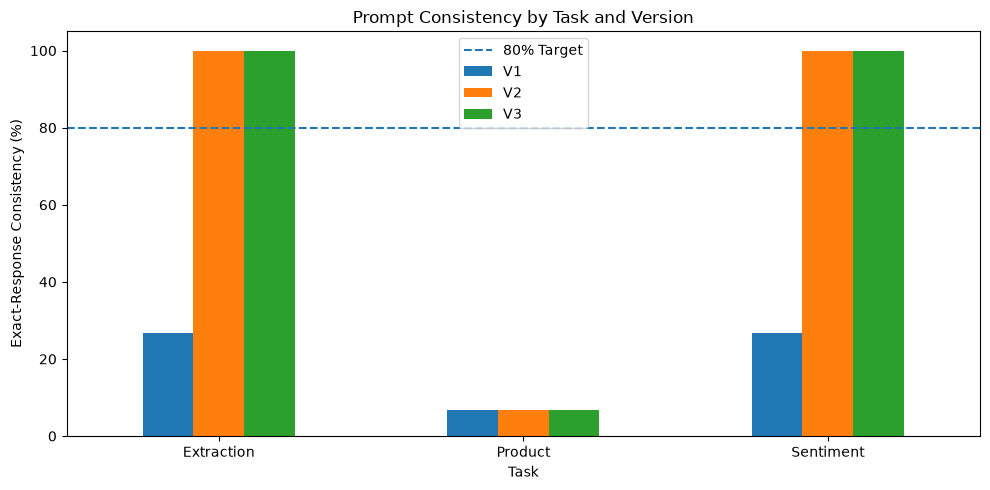

In [77]:
import matplotlib.pyplot as plt

comparison_chart = final_results.pivot(
    index="Task",
    columns="Version",
    values="Consistency (%)"
)

comparison_chart.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Prompt Consistency by Task and Version")
plt.ylabel("Exact-Response Consistency (%)")
plt.xlabel("Task")
plt.axhline(
    y=80,
    linestyle="--",
    label="80% Target"
)
plt.legend()
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [78]:
quality_summary = pd.DataFrame({
    "Task": [
        "Sentiment V3",
        "Product V2",
        "Product V3",
        "Extraction V2",
        "Extraction V3"
    ],
    "Metric": [
        "Label accuracy",
        "Length compliance",
        "Length compliance",
        "JSON validity",
        "JSON validity"
    ],
    "Result (%)": [
        sentiment_evaluation_v3["Correct Label"].mean() * 100,
        product_evaluation_v2["Length Valid"].mean() * 100,
        product_evaluation_v3["Length Valid"].mean() * 100,
        extraction_evaluation_v2["Valid JSON"].mean() * 100,
        extraction_evaluation_v3["Valid JSON"].mean() * 100
    ]
})

display(quality_summary)

,Task,Metric,Result (%)
0,Sentiment V3,Label accuracy,100.0
1,Product V2,Length compliance,100.0
2,Product V3,Length compliance,100.0
3,Extraction V2,JSON validity,100.0
4,Extraction V3,JSON validity,100.0


In [79]:
final_results.to_csv(
    "final_prompt_comparison.csv",
    index=False
)

quality_summary.to_csv(
    "prompt_quality_summary.csv",
    index=False
)

print("Final results saved successfully.")

Final results saved successfully.


## Final Analysis and Conclusions

### 1. Comparison of Prompt Versions

The experiments compared three prompt versions (V1, V2, and V3) across sentiment analysis, product description generation, and data extraction. Each version was tested 15 times to evaluate exact-response consistency.

**Sentiment Analysis**

- V1 achieved approximately 13.3% consistency.
- V2 achieved 100% consistency.
- V3 maintained 100% consistency.

The results show that adding explicit classification labels and output constraints significantly improved consistency. The few-shot examples introduced in V3 did not produce an additional measurable improvement over V2.

V3 also achieved 100% label accuracy on the tested positive customer message. However, testing a single message is insufficient to establish accuracy across more complex or ambiguous customer feedback.

**Product Description Generation**

- V1, V2, and V3 all achieved approximately 6.7% exact-response consistency.
- V2 and V3 both achieved 100% compliance with the specified word-count requirement.

The low consistency is understandable because product descriptions are generative outputs. Different wording does not necessarily indicate poor performance.

Structured instructions and few-shot examples did not improve exact-response consistency, but both versions successfully met the measured length requirement.

Additional evaluation would be needed to compare tone, structure, factual accuracy, and the presence of unsupported product features.

**Data Extraction**

- V1 achieved approximately 46.7% consistency.
- V2 achieved 100% consistency.
- V3 maintained 100% consistency.
- Both V2 and V3 achieved 100% JSON validity.

Introducing an explicit JSON output structure significantly improved consistency compared with the initial zero-shot prompt.

The step-by-step instructions introduced in V3 did not produce an additional measurable improvement over V2.

However, valid JSON does not automatically guarantee accurate extraction. The extracted values must also be checked against the original customer feedback.

### 2. Key Findings

The experiments produced three main findings:

1. **Clear instructions improve reliability for constrained tasks.** Sentiment analysis and data extraction benefited substantially from explicit output requirements.

2. **More complex prompting is not always better.** Few-shot examples and step-by-step instructions did not improve the measured consistency beyond V2 in these experiments.

3. **Evaluation metrics must match the task.** Exact-response consistency is useful for fixed-label classification and standardized extraction, but it is less meaningful for creative text generation. Product descriptions should be evaluated primarily against requirements such as length, accuracy, structure, and tone.

### 3. Limitations

The experiments used a limited number of input examples and 15 runs per prompt version. Therefore, the results demonstrate behavior under the tested conditions rather than general reliability across all possible inputs.

The evaluation also focused primarily on exact-response consistency and selected quality metrics. It did not comprehensively measure semantic correctness, factual accuracy, or performance on difficult and ambiguous cases.

### 4. Final Recommendations

**Sentiment Analysis:** V2 is the preferred option based on the available evidence. It achieved 100% exact-response consistency using simpler instructions, without requiring few-shot examples.

**Product Description Generation:** V2 is the preferred starting point. It achieved 100% length compliance without the additional prompt complexity of V3. Further evaluation is required before selecting a final production prompt.

**Data Extraction:** V2 is the preferred option based on the measured results. It achieved 100% exact-response consistency and JSON validity without the additional step-by-step instructions introduced in V3. Extraction accuracy and field-level validation should